# Sensor Data

## Reading data

In [1]:
import pandas as pd

# read data
columns = ['date', 'time', 'epoch', 'moteid', 'temperature', 'humidity', 'light', 'voltage']
df = pd.read_csv('datasets/data.txt', sep=' ', names=columns)
df

,date,time,epoch,moteid,temperature,humidity,light,voltage
0,2004-03-31,03:38:15.757551,2,1.0,122.1530,-3.91901,11.04,2.03397
1,2004-02-28,00:59:16.02785,3,1.0,19.9884,37.09330,45.08,2.69964
2,2004-02-28,01:03:16.33393,11,1.0,19.3024,38.46290,45.08,2.68742
3,2004-02-28,01:06:16.013453,17,1.0,19.1652,38.80390,45.08,2.68742
4,2004-02-28,01:06:46.778088,18,1.0,19.1750,38.83790,45.08,2.69964
...,...,...,...,...,...,...,...,...
2313677,2004-04-02,01:14:54.164318,61274,NaN,NaN,NaN,NaN,NaN
2313678,2004-04-02,01:17:53.670524,61275,NaN,NaN,NaN,NaN,NaN
2313679,2004-04-02,01:20:52.807972,61276,NaN,NaN,NaN,NaN,NaN
2313680,2004-04-02,01:26:53.950342,61278,NaN,NaN,NaN,NaN,NaN


## Data Cleanup

In [2]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2313682 entries, 0 to 2313681
Data columns (total 8 columns):
 #   Column       Dtype  
---  ------       -----  
 0   date         str    
 1   time         str    
 2   epoch        int64  
 3   moteid       float64
 4   temperature  float64
 5   humidity     float64
 6   light        float64
 7   voltage      float64
dtypes: float64(5), int64(1), str(2)
memory usage: 196.1 MB


### Time

In [3]:
df['timestamp'] = pd.to_datetime(df["date"] + ' ' + df["time"], format='mixed', errors='coerce')
df = df.drop(columns=['date', 'time'])

### Missing values

In [4]:
df.isna().sum()
df = df.dropna(subset=['timestamp', 'moteid', 'temperature'])
df

,epoch,moteid,temperature,humidity,light,voltage,timestamp
0,2,1.0,122.1530,-3.91901,11.04,2.033970,2004-03-31 03:38:15.757551
1,3,1.0,19.9884,37.09330,45.08,2.699640,2004-02-28 00:59:16.027850
2,11,1.0,19.3024,38.46290,45.08,2.687420,2004-02-28 01:03:16.333930
3,17,1.0,19.1652,38.80390,45.08,2.687420,2004-02-28 01:06:16.013453
4,18,1.0,19.1750,38.83790,45.08,2.699640,2004-02-28 01:06:46.778088
...,...,...,...,...,...,...,...
2313151,62426,58.0,24.1240,21.58390,1670.72,2.788360,2004-04-02 09:08:52.189274
2313152,62427,58.0,24.1044,21.43670,1729.60,2.788360,2004-04-02 09:09:22.206544
2313153,35112,6485.0,262.6560,NaN,NaN,0.393324,2004-03-23 21:32:16.223693
2313154,30493,33117.0,-36.2048,NaN,NaN,0.144859,2004-03-09 15:04:42.202647


### Invalid Sensor Id

In [6]:
# id senzorov su mimo rozsah 1-54
# vypisem pocetnost hodnot v stlpci moteid
df['moteid'].value_counts().sort_index()

# filter, pomocu ktoreho vyfiltrujeme len moteid v rozsahu <1, 54>
(df['moteid'] >= 1) & (df['moteid'] <= 54)

# da sa filter napisat pomocou metody .between() ako v SQL:
# SELECT *
# FROM data
# WHERE 
# moteid BETWEEN 1 AND 54
df = df.loc[ df['moteid'].between(1, 54) ]
df

,epoch,moteid,temperature,humidity,light,voltage,timestamp
0,2,1.0,122.1530,-3.91901,11.04,2.03397,2004-03-31 03:38:15.757551
1,3,1.0,19.9884,37.09330,45.08,2.69964,2004-02-28 00:59:16.027850
2,11,1.0,19.3024,38.46290,45.08,2.68742,2004-02-28 01:03:16.333930
3,17,1.0,19.1652,38.80390,45.08,2.68742,2004-02-28 01:06:16.013453
4,18,1.0,19.1750,38.83790,45.08,2.69964,2004-02-28 01:06:46.778088
...,...,...,...,...,...,...,...
2303285,65510,54.0,21.4780,47.63610,0.46,2.35683,2004-03-21 18:53:27.558979
2303286,65512,54.0,21.4780,47.63610,0.46,2.34751,2004-03-21 18:54:43.117051
2303287,65518,54.0,21.4192,47.66870,0.46,2.34751,2004-03-21 18:57:30.336879
2303288,65522,54.0,21.3996,47.70130,0.46,2.34751,2004-03-21 18:59:36.673512


### Invalid Physical Values

In [12]:
df.describe()

,epoch,moteid,temperature,humidity,light,voltage,timestamp
count,2.302918e+06,2.302918e+06,2.302918e+06,2.302918e+06,2.210084e+06,2.302918e+06,2302918
mean,3.295613e+04,2.837789e+01,3.928479e+01,3.388482e+01,4.076119e+02,2.490989e+00,2004-03-13 00:37:11.342355
min,0.000000e+00,1.000000e+00,-3.840000e+01,-8.983130e+03,0.000000e+00,9.100830e-03,2004-02-28 00:58:46.002832
25%,1.752100e+04,1.700000e+01,2.041960e+01,3.187760e+01,3.956000e+01,2.385220e+00,2004-03-05 07:30:30.888742
50%,3.317200e+04,2.900000e+01,2.244820e+01,3.928030e+01,1.582400e+02,2.527320e+00,2004-03-12 06:36:29.843780
75%,4.762000e+04,4.100000e+01,2.706400e+01,4.358550e+01,5.667200e+02,2.627960e+00,2004-03-20 04:00:21.936197
max,6.553500e+04,5.400000e+01,3.855680e+02,1.375120e+02,1.847360e+03,3.159150e+00,2004-04-03 16:51:34.171452
std,1.833407e+04,1.487200e+01,3.747919e+01,1.734838e+01,5.401490e+02,1.777763e-01,NaN


<Axes: title={'center': 'humidity'}, xlabel='moteid'>

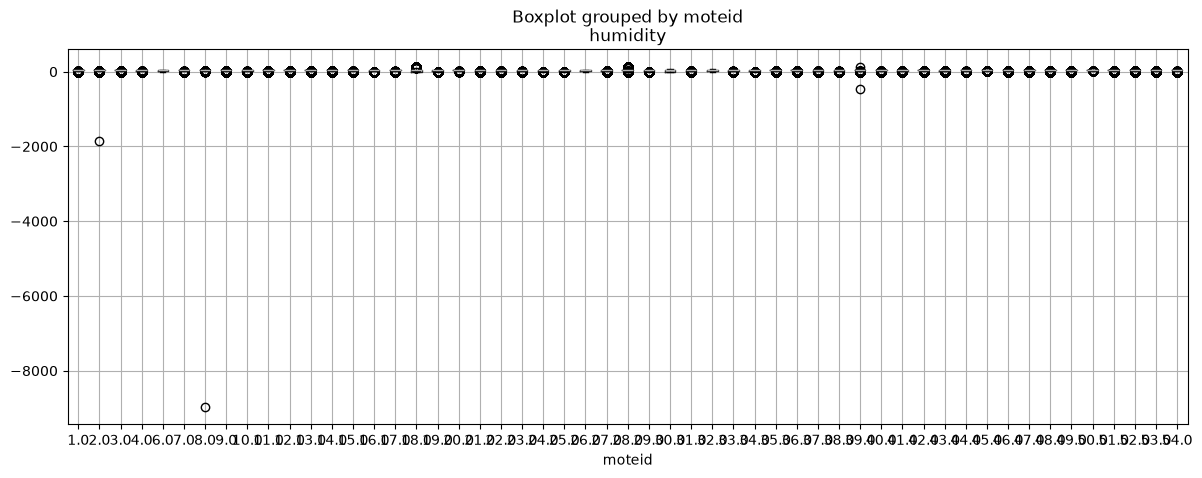

In [22]:
df.boxplot(column='humidity', by='moteid', figsize=(14, 5))

In [24]:
df = df.loc[
    df['temperature'].between(10, 35) & df['humidity'].between(0, 100)
    ]

<Axes: title={'center': 'humidity'}, xlabel='moteid'>

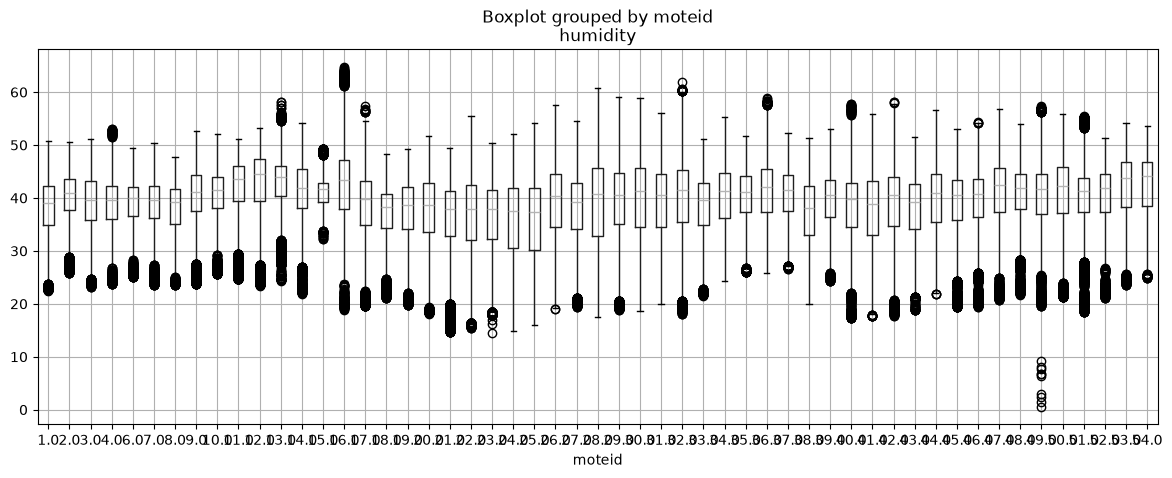

In [25]:
df.boxplot(column='humidity', by='moteid', figsize=(14, 5))

In [28]:
sensor = df[df["moteid"] == 1].sort_values("timestamp")

In [29]:
sensor


,epoch,moteid,temperature,humidity,light,voltage,timestamp
1,3,1.0,19.9884,37.0933,45.08,2.69964,2004-02-28 00:59:16.027850
2,11,1.0,19.3024,38.4629,45.08,2.68742,2004-02-28 01:03:16.333930
3,17,1.0,19.1652,38.8039,45.08,2.68742,2004-02-28 01:06:16.013453
4,18,1.0,19.1750,38.8379,45.08,2.69964,2004-02-28 01:06:46.778088
5,22,1.0,19.1456,38.9401,45.08,2.68742,2004-02-28 01:08:45.992524
...,...,...,...,...,...,...,...
22516,32925,1.0,34.8256,49.5167,0.92,2.29313,2004-03-23 03:18:32.052394
22517,32926,1.0,34.8648,49.4845,0.92,2.29313,2004-03-23 03:18:59.302173
22518,32927,1.0,34.8942,49.5167,0.92,2.29313,2004-03-23 03:19:37.894691
22520,32929,1.0,34.9726,49.4845,0.92,2.29313,2004-03-23 03:20:33.004466


In [40]:
df.info()


<class 'pandas.DataFrame'>
Index: 1868822 entries, 1 to 2303289
Data columns (total 7 columns):
 #   Column       Dtype         
---  ------       -----         
 0   epoch        int64         
 1   moteid       float64       
 2   temperature  float64       
 3   humidity     float64       
 4   light        float64       
 5   voltage      float64       
 6   timestamp    datetime64[us]
dtypes: datetime64[us](1), float64(5), int64(1)
memory usage: 114.1 MB


In [45]:
df['temperature'] = df['temperature'].astype('float32')
df['humidity'] = df['humidity'].astype('float32')
df['light'] = df['light'].astype('float32')
df['voltage'] = df['voltage'].astype('float32')

In [46]:
df.info()

<class 'pandas.DataFrame'>
Index: 1868822 entries, 1 to 2303289
Data columns (total 7 columns):
 #   Column       Dtype         
---  ------       -----         
 0   epoch        int64         
 1   moteid       float64       
 2   temperature  float32       
 3   humidity     float32       
 4   light        float32       
 5   voltage      float32       
 6   timestamp    datetime64[us]
dtypes: datetime64[us](1), float32(4), float64(1), int64(1)
memory usage: 85.5 MB


In [50]:
df['moteid'] = df['moteid'].astype('category')

In [51]:
df.info()

<class 'pandas.DataFrame'>
Index: 1868822 entries, 1 to 2303289
Data columns (total 7 columns):
 #   Column       Dtype         
---  ------       -----         
 0   epoch        int64         
 1   moteid       category      
 2   temperature  float32       
 3   humidity     float32       
 4   light        float32       
 5   voltage      float32       
 6   timestamp    datetime64[us]
dtypes: category(1), datetime64[us](1), float32(4), int64(1)
memory usage: 73.1 MB
